# Event-locked kernels, M2: PFC (El-Gaby deposit)

Loads and plots only. Numbers come from `run_event_kernels.py` and `run_population_drift.py`, one
job per recday through `sbatch_files/submit_event_kernels.sh`, merged with `--merge`. Write-ups:
`code/EVENT_KERNELS.md` (2026-10-12 entry) and `code/POPULATION_DRIFT.md`.

- Design: `kin='strict'`; analysis sessions are ABCD sessions with >= 10 trials (LEC also >= 5 as a
  sensitivity arm); leave one session out; Freedman-Lane, n_perm 100.
- A unit is **locked** to a block when p < 0.05 and its held-out cpd > 0. The exact null rate of
  p < 0.05 at n_perm 100 is 5/101.
- Every summary is per mouse: the recday mean, then the mouse mean (the `anatomy_split` convention).

PFC has no tracking before the first A or after the last trial, so `strict` zeroes the fast event blocks there and the entry kernel's first seconds carry no kinematic control: no first-minute kinematic claims.

In [1]:
RUN_MODE = 'load'   # never computes; rerun the sbatch jobs and merges instead
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import event_kernels_plots as P
%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
fig_path = lambda name: os.path.join(P.FIG_DIR, name)
drift_path = lambda name: os.path.join(P.DRIFT_FIG_DIR, name)
F = P.load_latest(os.path.join(P.STAGE1_DIR, 'stage1_pfc_kin-strict_mt10_np100'))
D = P.load_latest(os.path.join(P.DRIFT_DIR, 'drift_pfc_mt10'))
print(os.path.basename(F['_path']), os.path.basename(D['_path']), sep='\n')

stage1_pfc_kin-strict_mt10_np100.pkl
drift_pfc_mt10.pkl


## Run summary

In [2]:
P.table_run_summary({'PFC': F})

,dataset,anchor,recdays,skipped,units,sessions,rank_only_duplicates,r2_cv_median_of_recdays,reset_skipped,n_perm,kin,min_trials
0,PFC,entry,25,1,1229,171,True,0.040478,4,100,strict,10
1,PFC,first_A,25,1,1229,171,False,0.037784,0,100,strict,10


## F11. Per recday

The reset test is skipped on the four recdays with synthetic session tokens (no wall clock).

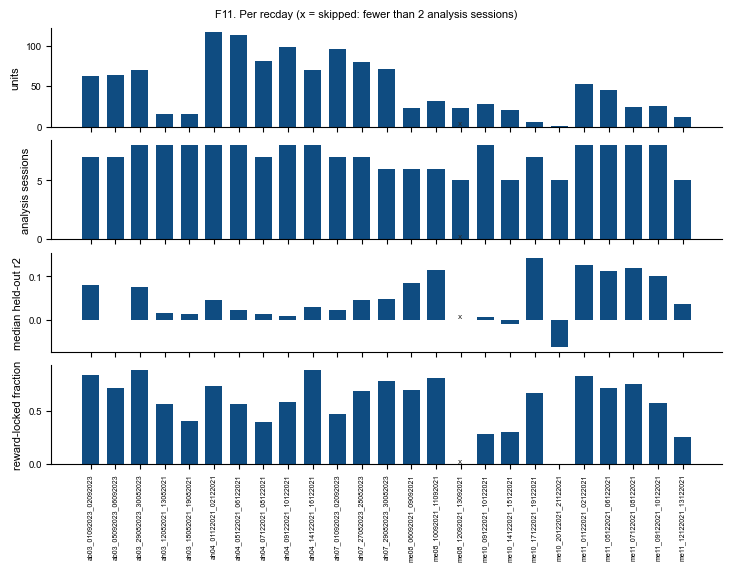

,recday,anchor,n_units,n_sessions,skipped,fold_rank_min,n_cols,n_rows,null_columns,rank_benign,r2_cv_median,reset,elapsed_s,slurm_job_id
0,ab03_01092023_02092023,entry,63,7,None,148.0,148.0,34572.0,,True,0.079601,ok,286.488134,3751711
1,ab03_05092023_06092023,entry,64,7,None,149.0,149.0,34342.0,,True,-0.000924,ok,406.741092,3751713
2,ab03_29082023_30082023,entry,70,8,None,148.0,148.0,33989.0,,True,0.076371,no wall clock for every session,271.035865,3751715
3,ah03_12082021_13082021,entry,16,8,None,149.0,149.0,39427.0,,True,0.015066,ok,107.755819,3751717
4,ah03_18082021_19082021,entry,15,8,None,149.0,149.0,39216.0,,True,0.012635,ok,128.623013,3751719
5,ah04_01122021_02122021,entry,117,8,None,146.0,146.0,36921.0,,True,0.044605,ok,498.548651,3751721
6,ah04_05122021_06122021,entry,114,8,None,146.0,146.0,38954.0,,True,0.021261,ok,1525.729280,3751723
7,ah04_07122021_08122021,entry,81,7,None,147.0,147.0,34135.0,,True,0.012802,ok,865.214460,3751725
8,ah04_09122021_10122021,entry,99,8,None,145.0,145.0,38947.0,,True,0.008489,ok,1341.119622,3751727
9,ah04_14122021_16122021,entry,70,8,None,145.0,145.0,39262.0,,True,0.030225,ok,965.728879,3751729


In [3]:
P.plot_recday_qc({'PFC': F}, out_path=fig_path('F11_recday_qc_PFC')); plt.show()
F['summary']

## F4. Kernel heatmaps

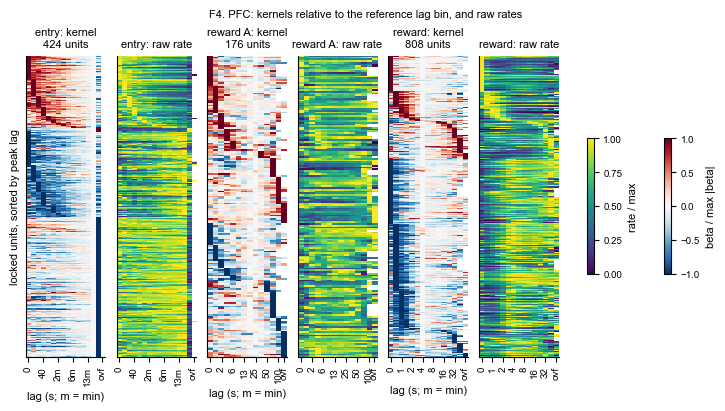

In [4]:
P.plot_kernel_heatmaps(F, 'PFC', out_path=fig_path('F4_kernels_PFC')); plt.show()

## Where the entry kernels peak

In [5]:
P.table_entry_peak_bins({'PFC': F}).round(3)

,mouse,overflow_f,first_minute_f,dataset
0,ab03,0.0,0.619,PFC
1,ah03,0.0,0.750,PFC
2,ah04,0.0,0.353,PFC
3,ah07,0.0,0.668,PFC
4,me08,0.0,0.180,PFC
5,me10,0.0,0.611,PFC
6,me11,0.0,0.287,PFC
